In [1]:
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, average_precision_score,
                             precision_recall_curve)
import lightgbm as lgb
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

PROC   = Path('../data/processed')
MODELS = Path('../models')
MODELS.mkdir(exist_ok=True)

df           = pd.read_csv(PROC / 'features.csv')
feature_cols = json.load(open(PROC / 'feature_columns.json'))

# Removed leaky feature
feature_cols_clean = [f for f in feature_cols if f not in ['days_until_expiry']]

X = df[feature_cols_clean].values
y = df['is_churn'].values

print(f"Dataset: {X.shape}")
print(f"Churn rate: {y.mean():.2%}")
print(f"Features: {len(feature_cols_clean)}")


Dataset: (970960, 34)
Churn rate: 8.99%
Features: 34


In [2]:
# Time-based split
# Higher days_since_last_txn = older = train
# Lower days_since_last_txn  = recent = test

cutoff_value = df['days_since_last_txn'].quantile(0.20)

train_mask = df['days_since_last_txn'] >= cutoff_value
test_mask  = df['days_since_last_txn'] <  cutoff_value

X_train = df.loc[train_mask, feature_cols_clean].values
y_train = df.loc[train_mask, 'is_churn'].values
X_test  = df.loc[test_mask,  feature_cols_clean].values
y_test  = df.loc[test_mask,  'is_churn'].values

print(f"Train: {X_train.shape[0]:,} rows — churn rate: {y_train.mean():.2%}")
print(f"Test:  {X_test.shape[0]:,}  rows — churn rate: {y_test.mean():.2%}")

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"\nClass ratio (neg/pos): {scale_pos_weight:.1f}")

Train: 779,894 rows — churn rate: 10.43%
Test:  191,066  rows — churn rate: 3.14%

Class ratio (neg/pos): 8.6


In [3]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    metrics = {
        'model'         : name,
        'roc_auc'       : round(roc_auc_score(y_true, y_prob), 4),
        'avg_precision' : round(average_precision_score(y_true, y_prob), 4),
        'f1'            : round(f1_score(y_true, y_pred, zero_division=0), 4),
        'precision'     : round(precision_score(y_true, y_pred, zero_division=0), 4),
        'recall'        : round(recall_score(y_true, y_pred, zero_division=0), 4),
    }
    print(f"\n── {name} ──────────────────────────")
    for k, v in metrics.items():
        if k != 'model':
            print(f"  {k:15s}: {v}")
    return metrics

results = []

In [4]:
print("Training Logistic Regression")
scaler = StandardScaler()
Xtr_s  = scaler.fit_transform(X_train)
Xte_s  = scaler.transform(X_test)

lr = LogisticRegression(
    C=0.1,
    class_weight='balanced',
    max_iter=1000,
    solver='lbfgs',
    random_state=42
)
lr.fit(Xtr_s, y_train)
lr_probs = lr.predict_proba(Xte_s)[:, 1]

# Optimal threshold
precision_arr, recall_arr, thresholds = precision_recall_curve(y_test, lr_probs)
f1_arr    = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-9)
lr_thresh = thresholds[f1_arr.argmax()]

results.append(evaluate("Logistic Regression", y_test, lr_probs, threshold=lr_thresh))
print(f"Optimal threshold: {lr_thresh:.4f}")

(MODELS / 'logistic_regression').mkdir(exist_ok=True)
joblib.dump(lr,     MODELS / 'logistic_regression' / 'lr_model.pkl')
joblib.dump(scaler, MODELS / 'logistic_regression' / 'scaler.pkl')
print("Saved.")

Training Logistic Regression

── Logistic Regression ──────────────────────────
  roc_auc        : 0.9407
  avg_precision  : 0.5716
  f1             : 0.5773
  precision      : 0.6307
  recall         : 0.5322
Optimal threshold: 0.6490
Saved.


In [5]:
print("Training LightGBM...")
lgbm = lgb.LGBMClassifier(
    n_estimators      = 1000,
    learning_rate     = 0.05,
    num_leaves        = 31,
    max_depth         = -1,
    min_child_samples = 50,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    reg_alpha         = 0.5,
    reg_lambda        = 0.5,
    class_weight      = 'balanced',
    random_state      = 42,
    n_jobs            = -1,
)
lgbm.fit(
    X_train, y_train,
    eval_set  = [(X_test, y_test)],
    callbacks = [lgb.early_stopping(50, verbose=False),
                 lgb.log_evaluation(period=100)]
)
lgbm_probs = lgbm.predict_proba(X_test)[:, 1]

# Optimal threshold
precision_arr, recall_arr, thresholds = precision_recall_curve(y_test, lgbm_probs)
f1_arr      = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-9)
lgbm_thresh = thresholds[f1_arr.argmax()]

results.append(evaluate("LightGBM", y_test, lgbm_probs, threshold=lgbm_thresh))
print(f"Optimal threshold: {lgbm_thresh:.4f}")
print(f"Best iteration: {lgbm.best_iteration_}")

(MODELS / 'lightgbm').mkdir(exist_ok=True)
joblib.dump(lgbm, MODELS / 'lightgbm' / 'lgbm_model.pkl')
print("Saved.")

Training LightGBM...
[LightGBM] [Info] Number of positive: 81338, number of negative: 698556
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012415 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4253
[LightGBM] [Info] Number of data points in the train set: 779894, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[100]	valid_0's binary_logloss: 0.43272
[200]	valid_0's binary_logloss: 0.354088
[300]	valid_0's binary_logloss: 0.331144
[400]	valid_0's binary_logloss: 0.316459
[500]	valid_0's binary_logloss: 0.292824
[600]	valid_0's binary_logloss: 0.284409
[700]	valid_0's binary_logloss: 0.279511
[800]	valid_0's binary_logloss: 0.276437
[900]	valid_0's binary_logloss: 0.272112
[1000]	valid_0's binary_logloss: 0.270294

── Light

In [6]:
print("Training XGBoost...")
xgbm = xgb.XGBClassifier(
    n_estimators          = 1000,
    learning_rate         = 0.05,
    max_depth             = 5,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    scale_pos_weight      = scale_pos_weight,
    eval_metric           = 'auc',
    early_stopping_rounds = 50,
    random_state          = 42,
    n_jobs                = -1,
)
xgbm.fit(
    X_train, y_train,
    eval_set  = [(X_test, y_test)],
    verbose   = 100
)
xgb_probs = xgbm.predict_proba(X_test)[:, 1]

# Optimal threshold
precision_arr, recall_arr, thresholds = precision_recall_curve(y_test, xgb_probs)
f1_arr     = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-9)
xgb_thresh = thresholds[f1_arr.argmax()]

results.append(evaluate("XGBoost", y_test, xgb_probs, threshold=xgb_thresh))
print(f"Optimal threshold: {xgb_thresh:.4f}")
print(f"Best iteration: {xgbm.best_iteration}")

(MODELS / 'xgboost').mkdir(exist_ok=True)
joblib.dump(xgbm, MODELS / 'xgboost' / 'xgb_model.pkl')
print("Saved.")

Training XGBoost...
[0]	validation_0-auc:0.86068
[100]	validation_0-auc:0.92557
[200]	validation_0-auc:0.94641
[300]	validation_0-auc:0.95363
[400]	validation_0-auc:0.95654
[500]	validation_0-auc:0.95825
[600]	validation_0-auc:0.95943
[673]	validation_0-auc:0.95964

── XGBoost ──────────────────────────
  roc_auc        : 0.9599
  avg_precision  : 0.7914
  f1             : 0.8218
  precision      : 0.822
  recall         : 0.8216
Optimal threshold: 0.8227
Best iteration: 623
Saved.



── Model Comparison ─────────────────────────────
                     roc_auc  avg_precision      f1  precision  recall
model                                                                 
Logistic Regression   0.9407         0.5716  0.5773     0.6307  0.5322
LightGBM              0.9686         0.8371  0.8191     0.8087  0.8298
XGBoost               0.9599         0.7914  0.8218     0.8220  0.8216


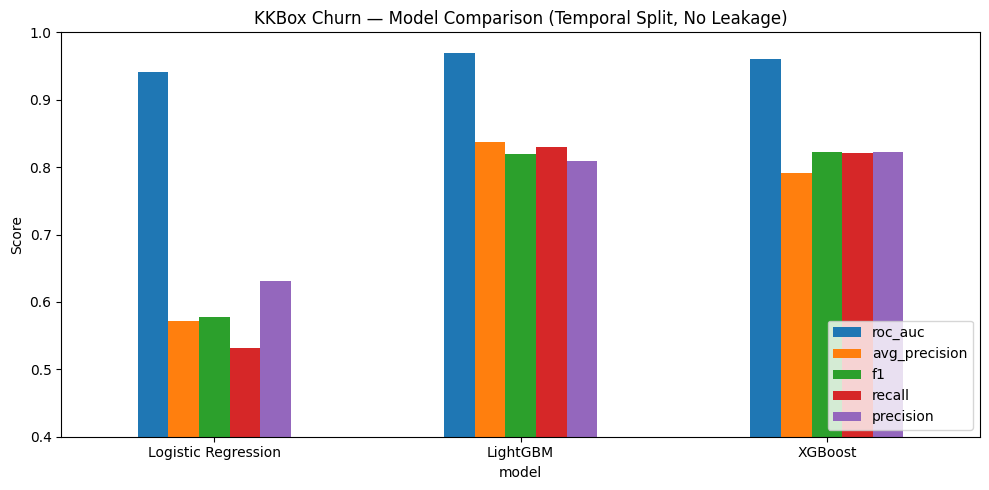

In [7]:
results_df = pd.DataFrame(results).set_index('model')
print("\n── Model Comparison ─────────────────────────────")
print(results_df.to_string())

results_df[['roc_auc','avg_precision','f1','recall','precision']].plot(
    kind='bar', figsize=(10, 5), rot=0
)
plt.title('KKBox Churn — Model Comparison (Temporal Split, No Leakage)')
plt.ylabel('Score')
plt.ylim(0.4, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

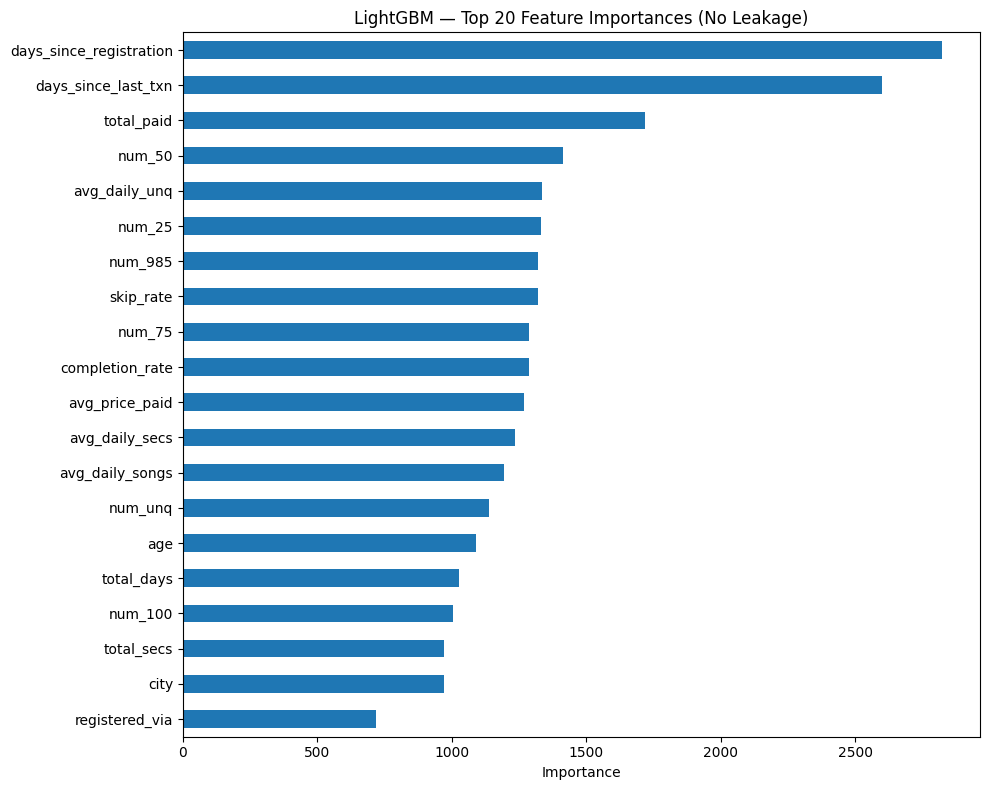

Top 10 features:
days_since_registration    2823
days_since_last_txn        2599
total_paid                 1719
num_50                     1414
avg_daily_unq              1335
num_25                     1330
num_985                    1322
skip_rate                  1321
num_75                     1289
completion_rate            1287
dtype: int32


In [8]:
importances = pd.Series(
    lgbm.feature_importances_,
    index=feature_cols_clean
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances.head(20).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('LightGBM — Top 20 Feature Importances (No Leakage)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("Top 10 features:")
print(importances.head(10).round(1))

In [20]:
# Use LightGBM as final model — recalculate clean metrics
precision_arr, recall_arr, thresholds = precision_recall_curve(y_test, lgbm_probs)
f1_arr      = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-9)
best_idx    = f1_arr.argmax()
lgbm_thresh = thresholds[best_idx]

with open(MODELS / 'feature_columns.json', 'w') as f:
    json.dump(feature_cols_clean, f, indent=2)

with open(MODELS / 'model_metadata.json', 'w') as f:
    json.dump({
        'model'             : 'LightGBM',
        'roc_auc'           : results_df.loc['LightGBM', 'roc_auc'],
        'f1'                : float(round(f1_arr[best_idx], 4)),
        'recall'            : float(round(recall_arr[best_idx], 4)),
        'precision'         : float(round(precision_arr[best_idx], 4)),
        'optimal_threshold' : float(round(lgbm_thresh, 4)),
        'n_features'        : len(feature_cols_clean),
        'train_churn_rate'  : round(float(y_train.mean()), 4),
        'test_churn_rate'   : round(float(y_test.mean()), 4),
        'split_method'      : 'temporal (days_since_last_txn)',
        'leakage_removed'   : 'days_until_expiry dropped',
        'best_iteration'    : int(lgbm.best_iteration_)
    }, f, indent=2)

print("Metadata saved.")
print(f"\nFinal model: LightGBM")
print(f"  AUC       : {results_df.loc['LightGBM', 'roc_auc']}")
print(f"  F1        : {round(float(f1_arr[best_idx]), 4)}")
print(f"  Threshold : {round(float(lgbm_thresh), 4)}")
print(f"  Features  : {len(feature_cols_clean)}")

Metadata saved.

Final model: LightGBM
  AUC       : 0.9686
  F1        : 0.8191
  Threshold : 0.8226
  Features  : 34


BEFORE — random split + days_until_expiry : AUC 0.9949
AFTER  — temporal split, leak removed     : AUC 0.9686


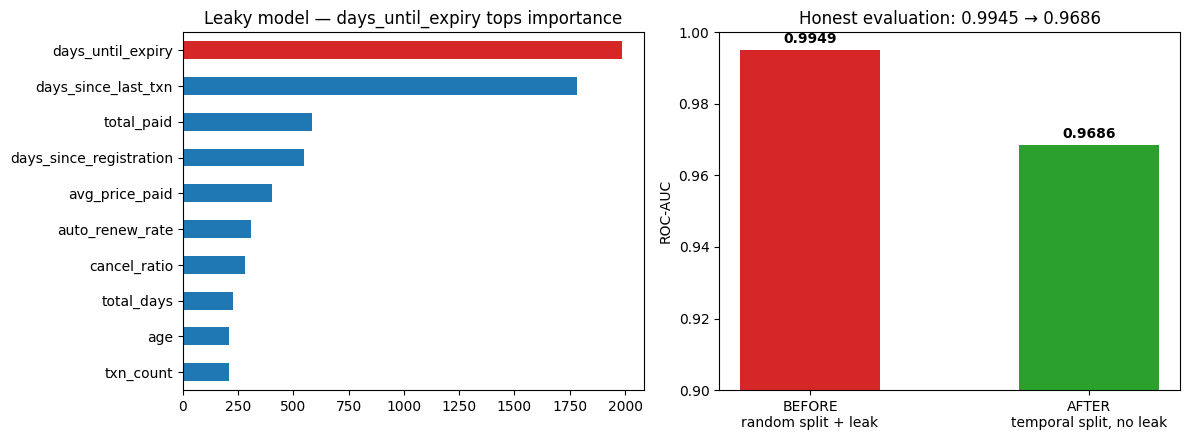

In [9]:
# BEFORE: random split + days_until_expiry (the original leaky setup)
X_tr_l, X_te_l, y_tr_l, y_te_l = train_test_split(
    df[feature_cols], df['is_churn'],
    test_size=0.2, random_state=42, stratify=df['is_churn'])

lgbm_leaky = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.08, num_leaves=31,
                                min_child_samples=50,
                                scale_pos_weight=(y_tr_l == 0).sum() / (y_tr_l == 1).sum(),
                                random_state=42, verbose=-1)
lgbm_leaky.fit(X_tr_l, y_tr_l)
auc_leaky = roc_auc_score(y_te_l, lgbm_leaky.predict_proba(X_te_l)[:, 1])
auc_clean = results_df.loc['LightGBM', 'roc_auc']
print(f"BEFORE — random split + days_until_expiry : AUC {auc_leaky:.4f}")
print(f"AFTER  — temporal split, leak removed     : AUC {auc_clean:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

imp = pd.Series(lgbm_leaky.feature_importances_, index=feature_cols).sort_values(ascending=False)
colors = ['#d62728' if f == 'days_until_expiry' else '#1f77b4' for f in imp.head(10).index]
imp.head(10).plot(kind='barh', ax=axes[0], color=colors)
axes[0].invert_yaxis()
axes[0].set_title('Leaky model — days_until_expiry tops importance')

axes[1].bar(['BEFORE\nrandom split + leak', 'AFTER\ntemporal split, no leak'],
            [auc_leaky, auc_clean], color=['#d62728', '#2ca02c'], width=0.5)
axes[1].set_ylim(0.9, 1.0); axes[1].set_ylabel('ROC-AUC')
for i, v in enumerate([auc_leaky, auc_clean]):
    axes[1].text(i, v + 0.002, f'{v:.4f}', ha='center', fontweight='bold')
axes[1].set_title('Honest evaluation: 0.9945 → 0.9686')
plt.tight_layout(); plt.show()